#Step 1 - Import required libraries

In [12]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Model saving
import joblib

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


#Step 2 - Load Dataset

In [13]:
# Step 2: Load Dataset

import os
from google.colab import files

file_path = None

for filename in [
    '/content/Telco-Customer-Churn.csv',
    '/content/Telco-Customer-Churn.txt'
]:
    if os.path.exists(filename):
        file_path = filename
        break

# Upload if the dataset is not already present
if file_path is None:
    uploaded = files.upload()
    file_path = next(iter(uploaded))

# Read CSV data
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


#Step 3 - Understand the Dataset

In [14]:
# Step 3: Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Records: 0


#Step 4. Data cleaning

In [16]:
# Step 4: Data Cleaning

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce'
)

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Handle missing TotalCharges
# Blank TotalCharges records in this dataset correspond
# to customers with zero tenure.
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify missing values
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Verify data types
print("\nUpdated data types:")
print(df.dtypes)

print("\nCleaned Dataset Shape:", df.shape)

Missing values before cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0


#Step 5. Exploratory Data Analysis (EDA)

Churn distribution

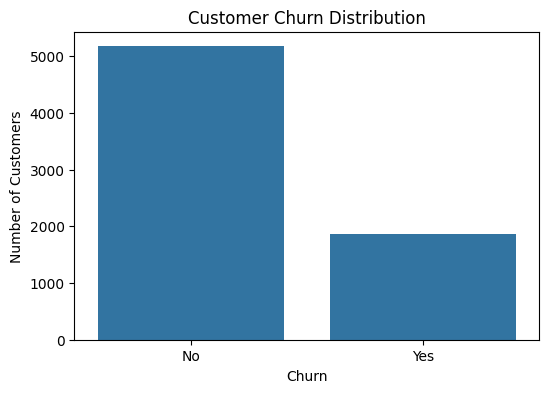

In [17]:
# Check how many customers stayed and left

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Churn percentage

In [18]:
# Calculate percentage of churned and retained customers

churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Tenure vs Churn

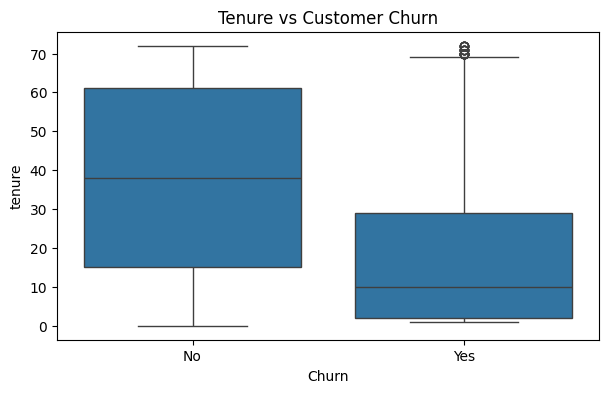

In [19]:
# Analyze customer tenure based on churn

plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title("Tenure vs Customer Churn")
plt.show()

Monthly Charges vs Churn

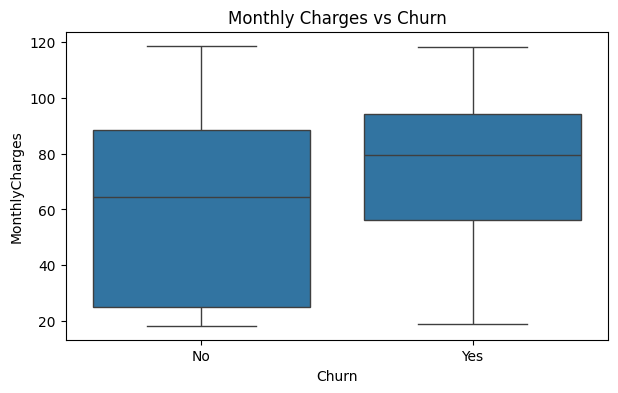

In [20]:
# Analyze monthly charges based on churn

plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title("Monthly Charges vs Churn")
plt.show()

Contract type vs Churn

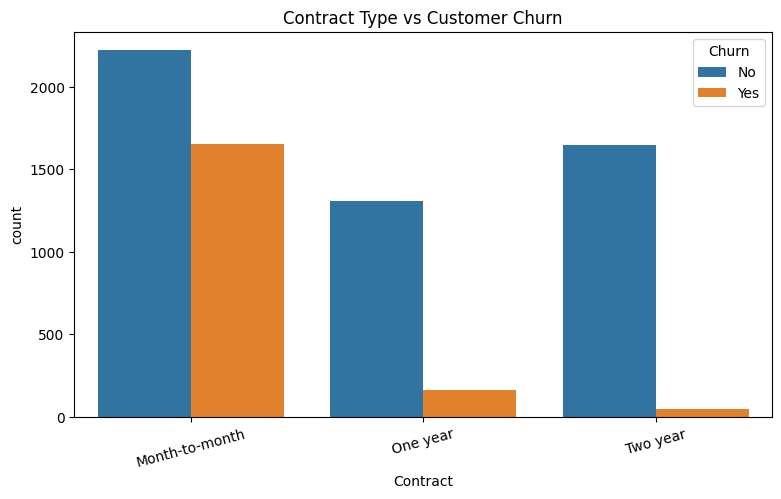

In [21]:
# Analyze the relationship between contract type and churn

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title("Contract Type vs Customer Churn")
plt.xticks(rotation=15)

plt.show()

#Step 6. Feature engineering

In [22]:
# Step 6: Feature Engineering

# Divide customer tenure into groups

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 60, 100],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-60 Months',
        'Above 60 Months'
    ]
)

# Display the newly created feature
print(df[['tenure', 'TenureGroup']].head())

   tenure   TenureGroup
0       1   0-12 Months
1      34  25-48 Months
2       2   0-12 Months
3      45  25-48 Months
4       2   0-12 Months


#Step 7. Data preprocessing

In [23]:
# Step 7: Data Preprocessing

# Remove customerID because it is only an identifier
df.drop('customerID', axis=1, inplace=True)

# Separate independent and dependent variables

X = df.drop('Churn', axis=1)

y = df['Churn'].map({'Yes': 1, 'No': 0})

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Split the dataset into training and testing data.

In [24]:
# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (5634, 20)
Testing data shape: (1409, 20)


#Step 8. Train Logistic Regression

In [25]:
# Step 8: Logistic Regression Model

# Create a Machine Learning pipeline

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression training completed!")

Logistic Regression training completed!


#Step 9. Train Random Forest

In [26]:
# Step 9: Random Forest Model

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


#Step 10. Evaluate both models

In [27]:
# Step 10: Model Evaluation

def evaluate_model(y_test, predictions, model_name):

    print("\n", model_name)
    print("-" * 40)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test, predictions, zero_division=0))

    print("F1 Score:",
          f1_score(y_test, predictions, zero_division=0))


# Evaluate Logistic Regression
evaluate_model(
    y_test,
    lr_predictions,
    "Logistic Regression"
)

# Evaluate Random Forest
evaluate_model(
    y_test,
    rf_predictions,
    "Random Forest"
)


 Logistic Regression
----------------------------------------
Accuracy: 0.7331440738112136
Precision: 0.4983164983164983
Recall: 0.7914438502673797
F1 Score: 0.6115702479338843

 Random Forest
----------------------------------------
Accuracy: 0.7792760823278921
Precision: 0.6129032258064516
Recall: 0.4572192513368984
F1 Score: 0.5237366003062787


#Compare both models

In [28]:
# Compare model performance

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.733144,0.498316,0.791444,0.611570
1,Random Forest,0.779276,0.612903,0.457219,0.523737


#Confusion matrix

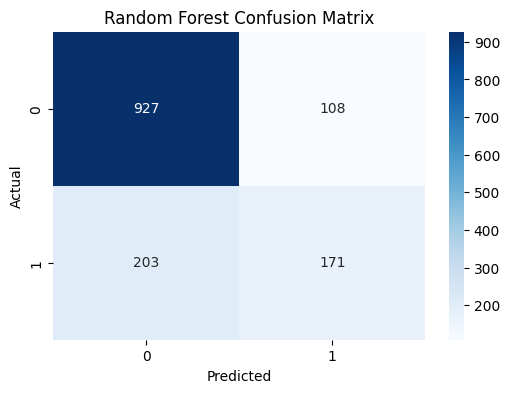

In [29]:
# Visualize Random Forest confusion matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

#Step 11. Save the trained models

In [30]:
# Step 11: Save trained Machine Learning models

joblib.dump(lr_model, 'logistic_regression_model.pkl')

joblib.dump(rf_model, 'random_forest_model.pkl')

print("Both models saved successfully!")

Both models saved successfully!
